In [3]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import os
import ast

countries_df = pd.read_csv(r"/workspaces/qgi-4.0/data/countries.csv")
patterns = pd.read_csv(r"/workspaces/qgi-4.0/data/ppr.csv")
SDCIS_CSVS = r"/workspaces/qgi-4.0/data/countries_sdci"

class Country:
    def __init__(self):
        self.name      = ""
        self.id        = ""
        self.patterns  = []
        self.sdcis     = []
        self.agg_sdcis = []

class Pattern:
    def __init__(self):
        self.country_a_id    = ""
        self.country_b_id    = ""
        self.pattern_length  = ""
        self.start_year_a_fk = ""
        self.start_year_b_fk = ""
        self.indexes         = ""
        self.avg_corr        = ""
        self.orgs            = ""
        self.power           = ""
        self.sectors         = []

class PatternsdciCouple:
    def __init__(self):
        self.pi_tuple = ()

class SDCI:
    def __init__(self):
        self.unique_id           = ""
        self.org_fk              = ""
        self.main_name_fk        = ""
        self.index_name_fk       = ""
        self.version_fk          = 0
        self.country_a_id_fk     = 0
        self.country_b_id_fk     = 0
        self.pattern_length_fk   = 0
        self.correlation         = 0.0
        self.start_year_a_fk     = 0
        self.index_values_a      = []
        self.start_year_b_fk     = 0
        self.index_values_b      = []
        self.creation_date       = ""
        self.sector              = ""

## Utils
def get_country_a_sdcis(country_a_id, folder_path = SDCIS_CSVS):
    country_a_id = int(country_a_id)
    if country_a_id > 0 and country_a_id < 251:
        country_a_id = str(country_a_id)
        for filename in os.listdir(folder_path):
            if filename.endswith('_solos_patterns.csv'):
                id_part = filename.split('_')[0]
                if id_part == country_a_id:
                    file_path = os.path.join(folder_path, filename)
                    try:
                        return pd.read_csv(file_path)
                    except Exception as e:
                        print(f"Error reading {filename}: {e}")
    print("No pattern file found for the specified country ID.")
    return None

def get_country_a_patterns(country_a_id, folder_path = SDCIS_CSVS):
    country_a_id = int(country_a_id)
    if country_a_id > 0 and country_a_id < 251:
        country_a_id = str(country_a_id)
        for filename in os.listdir(folder_path):
            if "_solos_" not in filename and filename.endswith('_patterns.csv'):
                id_part = filename.split('_')[0]
                if id_part == country_a_id:
                    file_path = os.path.join(folder_path, filename)
                    try:
                        return pd.read_csv(file_path)
                    except Exception as e:
                        print(f"Error reading {filename}: {e}")
    print("No pattern file found for the specified country ID: " + str(country_a_id))
    return None

def make_pattern(row):
    pattern = Pattern()
    pattern.country_a_id    = int(row["country_a_id_fk"])
    pattern.country_a       = get_name_by_id(pattern.country_a_id)
    pattern.country_b_id    = int(row["country_b_id_fk"])
    pattern.country_b       = get_name_by_id(pattern.country_b_id)
    pattern.pattern_length  = int(row["pattern_length_fk"])
    pattern.start_year_a_fk = int(row["start_year_a_fk"])
    pattern.start_year_b_fk = int(row["start_year_b_fk"])
    pattern.indexes         = int(row["indexes"])
    pattern.avg_corr        = round(row["avg_corr"], 6)
    try:
        pattern.orgs        = int(row["orgs"])
        pattern.sectors     = ast.literal_eval(row["Sectors"])
        pattern.power       = round(row["Power"], 6)
    except KeyError:
        pattern.orgs    = ""
        pattern.sectors = ""
        pattern.power   = ""
        print("Erring row: ")
        print(row)
        print("------------")
    
    
    return pattern

def show_country(country: Country, print_out = True):
    if print_out:
        print("Name: " + country.name)
        print("ID: "   + str(country.id))
        print("Number of Patterns: " + str(len(country.patterns)))
        print("Number of SDCIs: " + str(len(country.sdcis)))
        print("Number of Agg SDCIs: " + str(len(country.agg_sdcis)))
    return country.name, country.id, country.patterns, country.sdcis, country.agg_sdcis

def show_pattern(pattern, print_out = True):
    if print_out:
        print("country_a: "       + str(pattern.country_a))
        print("country_a_id: "    + str(pattern.country_a_id))
        print("country_b: "       + str(pattern.country_b))
        print("country_b_id: "    + str(pattern.country_b_id))
        print("pattern_length: "  + str(pattern.pattern_length))
        print("start_year_a_fk: " + str(pattern.start_year_a_fk))
        print("start_year_b_fk: " + str(pattern.start_year_b_fk))
        print("indexes: "         + str(pattern.indexes))
        print("avg_corr: "        + str(pattern.avg_corr))
        print("orgs: "            + str(pattern.orgs))
        print("power: "           + str(pattern.power))
        print("sectors: "         + str(pattern.sectors))
    return [
        pattern.country_a, pattern.country_a_id, pattern.country_b,
        pattern.country_b_id, pattern.pattern_length, pattern.start_year_a_fk,
        pattern.start_year_b_fk, pattern.indexes, pattern.avg_corr, pattern.orgs, 
        pattern.power, pattern.sectors
    ]

def show_sdci(sdci, print_out = True):
    if print_out:
        print("unique_id: "         + str(sdci.unique_id))
        print("org_fk: "            + str(sdci.org_fk))
        print("main_name_fk: "      + str(sdci.main_name_fk))
        print("index_name_fk: "     + str(sdci.index_name_fk))
        print("version_fk: "        + str(sdci.version_fk))
        print("country_a_id_fk: "   + str(sdci.country_a_id_fk))
        print("country_b_id_fk: "   + str(sdci.country_b_id_fk))
        print("pattern_length_fk: " + str(sdci.pattern_length_fk))
        print("correlation: "       + str(sdci.correlation))
        print("start_year_a_fk: "   + str(sdci.start_year_a_fk))
        print("index_values_a: "    + str(sdci.index_values_a))
        print("start_year_b_fk: "   + str(sdci.start_year_b_fk))
        print("index_values_b: "    + str(sdci.index_values_b))
        print("creation_date: "     + str(sdci.creation_date))
        print("sector: "            + str(sdci.sector))
    return [
        sdci.unique_id, sdci.org_fk, sdci.main_name_fk, sdci.index_name_fk,
        sdci.version_fk, sdci.country_a_id_fk, sdci.country_b_id_fk,
        sdci.pattern_length_fk, sdci.correlation, sdci.start_year_a_fk,
        sdci.index_values_a, sdci.start_year_b_fk, sdci.index_values_b,
        sdci.creation_date, sdci.sector
    ]

def get_sdci_for_pattern(pattern):
    sdcis = get_country_a_sdcis(pattern.country_a_id)
    sdcis = sdcis[sdcis["country_a_id_fk"]   == pattern.country_a_id]
    sdcis = sdcis[sdcis["country_b_id_fk"]   == pattern.country_b_id]
    sdcis = sdcis[sdcis["pattern_length_fk"] == pattern.pattern_length]
    sdcis = sdcis[sdcis["start_year_a_fk"]   == pattern.start_year_a_fk]
    sdcis = sdcis[sdcis["start_year_b_fk"]   == pattern.start_year_b_fk]
    return sdcis

def get_id_by_name(name):
    """
    Searches all name columns (name_1 to name_20) for the input name and returns the corresponding country ID.
    """
    for _, row in countries_df.iterrows():
        for i in range(1, 21):
            column = f"name_{i}"
            if column in row:
                current_value = row[column]
                if pd.notna(current_value) and current_value == name:
                    return row["id"]
    return None

def get_name_by_id(input_id):
    """
    Searches for the specified country ID and returns the primary name (name_1).
    """
    try:
        id_int = int(input_id)
        result = countries_df[countries_df["id"] == id_int]
        if not result.empty:
            return result["name_1"].iloc[0]
    except ValueError:
        pass  # Invalid ID format
    return None

def check_half_similarity(list1, list2):
    """
    Returns True if either list contains at least half of the elements of the other list.
    """
    # Create sets for efficient lookups
    set_list2 = set(list2)
    count1 = sum(1 for element in list1 if element in set_list2)
    
    set_list1 = set(list1)
    count2 = sum(1 for element in list2 if element in set_list1)
    
    # Check if either condition is met
    return (count1 >= len(list1) / 2) or (count2 >= len(list2) / 2)

def get_country(country_a_id):
    country      = Country()
    country.id   = country_a_id
    country.name = get_name_by_id(country_a_id)
    patterns_df  = get_country_a_patterns(country_a_id)
    if patterns_df is not None:
        for _, row in patterns_df.iterrows():
            country.patterns.append(make_pattern(row))
        return country
    return None

## Populating functions
def populate_countries_with_patterns(country_a_ids = range(1, 251)):
    if 0 in country_a_ids:
        print("Please make sure to not include `0` as a country ID in the passed `target_ids` parameter.")
        return None

    countries = []
    for country_a_id in country_a_ids:
        country = get_country(country_a_id)
        if country is not None:
            countries.append(country)
    return countries

def populate_sdcis_for_country(country):
    for pattern in country.patterns:
        pattern_sdcis_df = get_sdci_for_pattern(pattern)
        if len(pattern_sdcis_df) == 0:
            continue
        for i, row in pattern_sdcis_df.iterrows():
            sdci = SDCI()
            sdci.unique_id         = row["unique_id"]
            sdci.org_fk            = row["org_fk"]
            sdci.main_name_fk      = row["main_name_fk"]
            sdci.index_name_fk     = row["index_name_fk"]
            sdci.version_fk        = row["version_fk"]
            sdci.country_a_id_fk   = row["country_a_id_fk"]
            sdci.country_b_id_fk   = row["country_b_id_fk"]
            sdci.pattern_length_fk = row["pattern_length_fk"]
            sdci.correlation       = row["correlation"]
            sdci.start_year_a_fk   = row["start_year_a_fk"]
            sdci.index_values_a    = row["index_values_a"]
            sdci.start_year_b_fk   = row["start_year_b_fk"]
            sdci.index_values_b    = row["index_values_b"]
            sdci.creation_date     = row["creation_date"]
            sdci.sector            = row["Sector"]
            country.sdcis.append
        
        country.sdcis.append(sdci)

    return country

def merge_pass(current_list, special_func):
    """Helper function to process one pass of merging."""
    merged_list = []
    i = 0
    while i < len(current_list):
        # Check if there's a next element to form a pair
        if i + 1 < len(current_list):
            a, b = current_list[i], current_list[i + 1]
            result = special_func(a, b)
            if len(result) == 1:
                # Merge occurred; append merged item and skip next element
                merged_list.append(result[0])
                i += 2
            else:
                merged_list.append(a)
                i += 1
        else:
            # Append remaining element
            merged_list.append(current_list[i])
            i += 1
    return merged_list

def aggregate_sdcis(items, special_func):
    """Aggregates items by repeatedly merging possible pairs."""
    #current = items.copy()
    current = sorted(items.copy(), key=lambda x: x.index_name_fk)
    while True:
        next_current = merge_pass(current, special_func)
        if next_current == current:
            break
        current = next_current
    return current

def merge_sdcis(sdci_a: SDCI, sdci_b: SDCI):
    if (
        sdci_a.sector          == sdci_b.sector           and
        sdci_a.main_name_fk    == sdci_b.main_name_fk     and
        sdci_a.index_name_fk   == sdci_b.index_name_fk    and
        sdci_a.org_fk          == sdci_b.org_fk           and
        sdci_a.country_b_id_fk == sdci_b.country_b_id_fk
    ):
        a_start                    = min(sdci_a.start_year_a_fk, sdci_b.start_year_a_fk)
        a_end                      = max(sdci_a.start_year_a_fk + sdci_a.pattern_length_fk, sdci_b.start_year_a_fk + sdci_b.pattern_length_fk)
        b_start                    = min(sdci_a.start_year_b_fk, sdci_b.start_year_b_fk)
        b_end                      = max(sdci_a.start_year_b_fk + sdci_a.pattern_length_fk, sdci_b.start_year_b_fk + sdci_b.pattern_length_fk)

        agg_sdci                   = SDCI()
        agg_sdci.version_fk        = "+agg_a_" + str(sdci_a.version_fk) + "_b_" + str(sdci_b.version_fk) + "+"
        agg_sdci.unique_id         = "+agg_a_" + str(sdci_a.unique_id)  + "_b_" + str(sdci_b.unique_id)  + "+"
        agg_sdci.sector            = sdci_a.sector
        agg_sdci.index_name_fk     = sdci_a.index_name_fk
        agg_sdci.main_name_fk      = sdci_a.main_name_fk
        agg_sdci.org_fk            = sdci_a.org_fk

        agg_sdci.country_a_id_fk   = sdci_a.country_a_id_fk
        agg_sdci.country_b_id_fk   = sdci_a.country_b_id_fk

        agg_sdci.start_year_a_fk   = a_start
        agg_sdci.start_year_b_fk   = b_start
        agg_sdci.pattern_length_fk = max(a_end, b_end) - min(a_start, b_start)
        agg_sdci.correlation       = (sdci_a.correlation + sdci_b.correlation) / 2 # TODO: reconstruct indicator segment for these countries, and get correlation of it, place it here
        return [agg_sdci]
    else:
        return [sdci_a, sdci_b]

def sdcis_to_df(country_sdcis_list: list[SDCI]):
    unique_ids, orgs, main_names, index_names, versions, country_a_ids, country_b_ids = [], [], [], [], [], [], []
    patt_lengths, correlations, start_years_a, index_values_a, start_years_b, index_values_b = [], [], [], [], [], []
    creation_dates, sectors = [], []

    for sdci in country_sdcis_list:
        sdci_data = show_sdci(sdci, print_out = False)
        unique_ids.append(sdci_data[0])
        orgs.append(sdci_data[1])
        main_names.append(sdci_data[2])
        index_names.append(sdci_data[3])
        versions.append(sdci_data[4])
        country_a_ids.append(sdci_data[5])
        country_b_ids.append(sdci_data[6])
        patt_lengths.append(sdci_data[7])
        correlations.append(sdci_data[8])
        start_years_a.append(sdci_data[9])
        index_values_a.append(sdci_data[10])
        start_years_b.append(sdci_data[11])
        index_values_b.append(sdci_data[12])
        creation_dates.append(sdci_data[13])
        sectors.append(sdci_data[14])

    df = pd.DataFrame({
        "sdci_id":        unique_ids,
        "org":            orgs,
        "main_name":      main_names,
        "index_name":     index_names,
        "version":        versions,
        "country_a_id":   country_a_ids,
        "country_b_id":   country_b_ids,
        "pattern_length": patt_lengths,
        "correlation":    correlations,
        "start_year_a":   start_years_a,
        "index_values_a": index_values_a,
        "start_year_b":   start_years_b,
        "index_values_b": index_values_b 
    })
    return df.sort_values(by = "country_b_id")

def populate_countries_with_patterns_and_sdcis(country_a_ids = range(1, 251)):
    countries = populate_countries_with_patterns(country_a_ids)
    print("Populated all countries with patterns. ")
    for country in countries:
        print(country.name + "...")
        country = populate_sdcis_for_country(country = countries[0])
        country.agg_sdcis = aggregate_sdcis(country.sdcis, merge_sdcis)
    return countries

## Network analysis
def create_edge_list(countries):
    edges = []
    for country in countries:
        for sdci in country.agg_sdcis:
            edges.append({
                "source": sdci.country_a_id_fk,
                "target": sdci.country_b_id_fk,
                "weight": sdci.correlation,
                "sector": sdci.sector
            })
    return pd.DataFrame(edges)

def build_network(countries):
    G = nx.Graph()
    
    # Add nodes
    all_countries = [country.name for country in countries]
    G.add_nodes_from(all_countries)
    
    # Add edges
    edge_list = create_edge_list(countries)
    for _, row in edge_list.iterrows():
        G.add_edge(
            row["source"], 
            row["target"], 
            weight = row["weight"], 
            sector = row["sector"]
        )
    
    return G

def plot_network(G):
    plt.figure(figsize = (12, 8))
    pos = nx.spring_layout(G)  # Position nodes using force-directed layout
    nx.draw(
        G, 
        pos, 
        node_size   = [v * 1000 for v in nx.degree_centrality(G).values()],  # Node size = centrality
        edge_color  = "gray",
        width       = [G[u][v]["weight"] * 2 for u, v in G.edges()],  # Edge width = correlation
        with_labels = True
    )
    plt.show()


In [4]:
countries = populate_countries_with_patterns_and_sdcis(range(1, 91))
print("+++++++++++++++++++++++++++++++++++++")
G = build_network(countries)
centrality = nx.degree_centrality(G)
print("Most connected countries:", sorted(centrality.items(), key = lambda x: x[1], reverse = True)[:5])

No pattern file found for the specified country ID: 7
No pattern file found for the specified country ID: 8
No pattern file found for the specified country ID: 27
No pattern file found for the specified country ID: 30
No pattern file found for the specified country ID: 32
No pattern file found for the specified country ID: 46
No pattern file found for the specified country ID: 47
No pattern file found for the specified country ID: 51
No pattern file found for the specified country ID: 70
No pattern file found for the specified country ID: 75
No pattern file found for the specified country ID: 77
No pattern file found for the specified country ID: 83
No pattern file found for the specified country ID: 87
No pattern file found for the specified country ID: 90
Populated all countries with patterns. 
Afghanistan...
Albania...
Algeria...
American Samoa...
Andorra...
Angola...
Antigua and Barbuda...
Argentina...
Armenia...
Aruba...
Australia...
Austria...
Azerbaijan...
Bahamas...
Bahrain...


KeyboardInterrupt: 

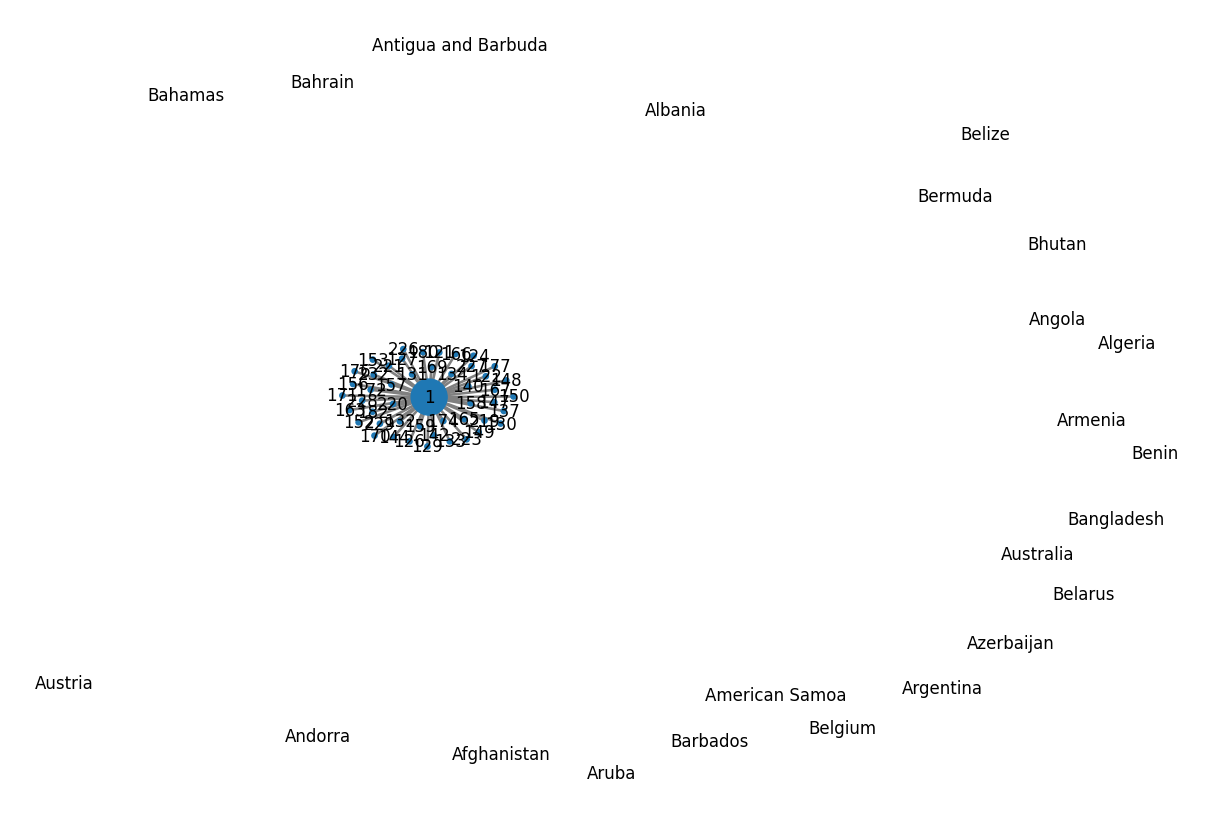

In [ ]:
plot_network(G)